# Colossus 1 — surface-temperature timeline and heat maps
**Complete Colab version.** Run cells from top to bottom using Runtime → Run all. Your Earth Engine project ID is already included; sign in when prompted.

The primary output is a **monthly timeline line chart**, not a distance bar chart. Images are processed one at a time to avoid the concurrent-aggregation error. The notebook also produces summer 2023/2025 heat maps.

This is exploratory land-surface temperature analysis. It does not establish air-temperature changes or prove a causal effect of the data center. The startup window (July–September 2024) is from your discussion notes. No satellite results are precomputed.

**Updated period:** 1 January 2020 through 29 October 2026. Latest usable imagery may be earlier because of satellite revisit, clouds and processing delays. Includes monthly and yearly average-temperature charts. 2026 is year-to-date.

The timeline now includes 2020–2022 as additional pre-startup years. The summer map comparison remains 2023 versus 2025. The merged collection uses whichever Landsat 8/9 images are available for each date; early years have fewer available satellites, so compare observation counts as well as temperatures.

In [ ]:
%pip -q install earthengine-api geemap pandas matplotlib

In [ ]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import time
import json
import hashlib
from pathlib import Path
from IPython.display import display
from google.colab import output, files

output.enable_custom_widget_manager()
PROJECT_ID = "ee-project-ntu-512407"
ee.Authenticate()
ee.Initialize(project=PROJECT_ID)
print("Earth Engine initialized.")

Earth Engine initialized.


## 1. Settings and location
Verify the cyan marker against the former Electrolux building before interpreting results. It is an approximate site center, not a surveyed boundary. The near-site area is a 500 m circle; the background is a 3–5 km ring.

Clouds, shadows, cirrus, snow, water and saturation are excluded. Additional uncertainty/cloud-distance thresholds are disabled by default to investigate the earlier coverage failure. If enabled, apply them consistently and rerun downstream cells. A 30 m output grid does not imply independent 30 m thermal measurements.

In [ ]:
LON, LAT = -90.15639, 35.06000
START_DATE, END_DATE = "2020-01-01", "2026-10-30"  # Exclusive: includes 29 Oct 2026
CRS, SCALE = "EPSG:32615", 30
MIN_VALID_DAYS_PER_MONTH = 1
MIN_PIXELS_NEAR = 100
MIN_PIXELS_BACKGROUND = 100
MIN_SUMMER_OBSERVATIONS = 2
MAX_UNCERTAINTY_K = None
MIN_CLOUD_DISTANCE_KM = None

site = ee.Geometry.Point([LON, LAT])
roi = site.buffer(5000)
near_site = site.buffer(500)
reference = roi.difference(site.buffer(3000), 1)

location_map = geemap.Map(center=[LAT, LON], zoom=14)
location_map.add_basemap("SATELLITE")
location_map.addLayer(site, {"color":"cyan"}, "Approximate Colossus 1")
outlines = ee.FeatureCollection([
    ee.Feature(near_site, {"area":"Near site"}),
    ee.Feature(reference, {"area":"Background"})
])
location_map.addLayer(
    outlines.style(color="ffff00", fillColor="00000000", width=2),
    {}, "Analysis areas"
)
display(location_map)

Map(center=[35.06, -90.15639], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topri…

## 2. Prepare Landsat temperatures
The conversion is °C = ST_B10 × 0.00341802 + 149 − 273.15. Only L2SP scenes with temperature products are considered.

In [ ]:
def prepare(im):
    qa = im.select("QA_PIXEL")
    mask = (qa.bitwiseAnd(63).eq(0)
            .And(qa.bitwiseAnd(128).eq(0))
            .And(im.select("QA_RADSAT").eq(0)))
    if MAX_UNCERTAINTY_K is not None:
        mask = mask.And(im.select("ST_QA").multiply(.01).lte(MAX_UNCERTAINTY_K))
    if MIN_CLOUD_DISTANCE_KM is not None:
        mask = mask.And(im.select("ST_CDIST").multiply(.01).gte(MIN_CLOUD_DISTANCE_KM))
    return (im.select("ST_B10").multiply(.00341802).add(149).subtract(273.15)
            .rename("LST_C").updateMask(mask)
            .copyProperties(im, ["system:time_start", "LANDSAT_PRODUCT_ID"]))

collection = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
    .filterBounds(roi).filterDate(START_DATE, END_DATE)
    .filter(ee.Filter.eq("PROCESSING_LEVEL", "L2SP"))
    .map(prepare).sort("system:time_start"))

def observation(image):
    image = ee.Image(image)
    reducer = ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True)
    def stats(region):
        return image.reduceRegion(
            reducer=reducer, geometry=region, scale=SCALE, crs=CRS,
            maxPixels=100000000, tileScale=4)
    near, background = stats(near_site), stats(reference)
    return ee.Feature(None, {
        "date": image.date().format("YYYY-MM-dd"),
        "scene": image.get("LANDSAT_PRODUCT_ID"),
        "near_C": near.get("LST_C_mean"),
        "background_C": background.get("LST_C_mean"),
        "near_pixels": near.get("LST_C_count"),
        "background_pixels": background.get("LST_C_count"),
    })

## 3. Process images sequentially
This cell can take several minutes. Progress appears every five images. Do not run duplicate processing cells in other tabs at the same time.

A local Colab checkpoint saves each result. If a request fails, rerun this cell to resume with the same settings. Changing settings creates a new checkpoint. The checkpoint lasts only as long as the Colab runtime storage.

In [ ]:
# Include all preparation settings and collection identity in the checkpoint key.
manifest = collection.aggregate_array("LANDSAT_PRODUCT_ID").getInfo()
if not manifest:
    raise ValueError("No scenes found. Check dates and location.")

config = {
    "version": 1, "project": PROJECT_ID, "lon": LON, "lat": LAT,
    "start": START_DATE, "end": END_DATE, "crs": CRS, "scale": SCALE,
    "uncertainty": MAX_UNCERTAINTY_K,
    "cloud_distance": MIN_CLOUD_DISTANCE_KM,
    "near_radius": 500, "background_radii": [3000,5000],
    "scenes": manifest
}
cache_key = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:16]
cache_path = Path(f"colossus_checkpoint_{cache_key}.json")
cache = json.loads(cache_path.read_text()) if cache_path.exists() else {}
number_of_images = len(manifest)
image_list = collection.toList(number_of_images)
print(f"{number_of_images} scenes; {len(cache)} results already saved.")

for i in range(number_of_images):
    key = str(i)
    if key not in cache:
        image = ee.Image(image_list.get(i))
        for attempt in range(4):
            try:
                result = observation(image).getInfo()
                break
            except ee.EEException as error:
                message = str(error).lower()
                quota_error = any(t in message for t in [
                    "too many concurrent aggregations", "429", "too many requests"])
                if not quota_error or attempt == 3:
                    raise
                delay = 15 * (attempt + 1)
                print(f"Earth Engine busy; retrying image {i+1} in {delay} seconds.")
                time.sleep(delay)
        cache[key] = result.get("properties", {})
        cache_path.write_text(json.dumps(cache))
    if (i+1) % 5 == 0 or i+1 == number_of_images:
        print(f"Processed {i+1}/{number_of_images}")

records = [cache[str(i)] for i in range(number_of_images)]
scene_data = pd.DataFrame(records).reindex(columns=[
    "date","scene","near_C","background_C","near_pixels","background_pixels"])
scene_data.to_csv("Colossus_all_scene_statistics.csv", index=False)
print("Processing complete.")

227 scenes; 0 results already saved.
Processed 5/227
Processed 10/227
Processed 15/227
Processed 20/227
Processed 25/227
Processed 30/227
Processed 35/227
Processed 40/227
Processed 45/227
Processed 50/227
Processed 55/227
Processed 60/227
Processed 65/227
Processed 70/227
Processed 75/227
Processed 80/227
Processed 85/227
Processed 90/227
Processed 95/227
Processed 100/227
Processed 105/227
Processed 110/227
Processed 115/227
Processed 120/227
Processed 125/227
Processed 130/227
Processed 135/227
Processed 140/227
Processed 145/227
Processed 150/227
Processed 155/227
Processed 160/227
Processed 165/227
Processed 170/227
Processed 175/227
Processed 180/227
Processed 185/227
Processed 190/227
Processed 195/227
Processed 200/227
Processed 205/227
Processed 210/227
Processed 215/227
Processed 220/227
Processed 225/227
Processed 227/227
Processing complete.


## 4. Build the monthly timeline
Pair near-site and background means on each acquisition, then calculate their difference. Dates with fewer than 100 valid output-grid pixels in either region are excluded as an exploratory coverage screen. This is not a statistical sample-size test; retained coverage can still vary substantially.

Same-day scenes are averaged before monthly aggregation. Months with fewer than two usable dates remain gaps; they are not interpolated.

In [ ]:
usable = scene_data.dropna(subset=["date","near_C","background_C"]).copy()
for column in ["near_C","background_C","near_pixels","background_pixels"]:
    usable[column] = pd.to_numeric(usable[column], errors="coerce")
usable = usable[
    (usable["near_pixels"] >= MIN_PIXELS_NEAR) &
    (usable["background_pixels"] >= MIN_PIXELS_BACKGROUND)
].copy()
if usable.empty:
    raise ValueError("No observations pass the coverage screen. Inspect Colossus_all_scene_statistics.csv; do not invent missing values.")

usable["date"] = pd.to_datetime(usable["date"])
usable["excess_C"] = usable["near_C"] - usable["background_C"]
daily = usable.groupby("date")[["near_C","background_C","excess_C"]].mean().sort_index()
monthly = daily.resample("MS").agg(
    near_C=("near_C","mean"),
    background_C=("background_C","mean"),
    excess_C=("excess_C","mean"),
    valid_days=("excess_C","count"))
months = pd.date_range(START_DATE, pd.Timestamp(END_DATE)-pd.Timedelta(days=1), freq="MS")
monthly = monthly.reindex(months)
monthly.index.name = "month"
monthly["valid_days"] = monthly["valid_days"].fillna(0).astype(int)
monthly.loc[monthly["valid_days"] < MIN_VALID_DAYS_PER_MONTH,
            ["near_C","background_C","excess_C"]] = np.nan
if monthly["excess_C"].notna().sum() == 0:
    raise ValueError("No month has enough usable dates. Inspect scene coverage first.")

daily.to_csv("Colossus_daily_temperatures.csv")
monthly.to_csv("Colossus_monthly_temperatures.csv")
display(monthly.round(2))

,near_C,background_C,excess_C,valid_days
month,,,,
2020-01-01,13.18,11.51,1.66,1
2020-02-01,14.48,12.83,1.65,1
2020-03-01,NaN,NaN,NaN,0
2020-04-01,25.59,22.54,3.05,1
2020-05-01,30.40,28.23,2.18,2
...,...,...,...,...
2026-06-01,42.20,32.36,9.85,2
2026-07-01,41.96,32.95,9.01,3
2026-08-01,40.64,31.64,9.00,2


## 5. Timeline line charts
The upper panel compares the two surface-temperature series. The middle panel shows their paired difference. A value of +2 °C means the near-site surface was 2 °C warmer than the background on average—not that the data center caused 2 °C of warming. The lower panel shows sampling.

Seasonality, land cover and varying spatial coverage can still influence these lines. No causal effect or statistical significance is inferred.

## Monthly and yearly average surface temperatures
Both charts compare the area within 500 m of the approximate site center with the 3–5 km background ring.

**Monthly:** arithmetic mean of usable daily observations; months with fewer than two usable dates remain gaps.

**Yearly:** arithmetic mean of all usable daily observations in that calendar year, giving each usable date equal weight. This is a clear-sky satellite sample average, not a continuous annual air-temperature average. The yearly mean can be biased toward seasons with more observations. The table reports usable dates and represented months; missing months are not treated as zero.

**2026 is year-to-date through 29 October**, subject to the latest usable image. Do not interpret its difference from full-year averages as a warming trend. Seasonal differences and sampling affect that comparison. The yearly line connects summaries for readability and is not a fitted trend.

Requested through: 29 October 2026
Latest usable paired observation: 18 October 2026


,near_C,background_C,excess_C,valid_days,months_with_data,months_meeting_monthly_minimum,first_observation,last_observation,period
year,,,,,,,,,
2020,26.78,24.00,2.78,14,10,10,2020-01-27,2020-12-28,Full calendar-year window
2021,26.67,23.72,2.96,17,10,10,2021-01-13,2021-12-23,Full calendar-year window
2022,28.39,24.93,3.46,20,11,11,2022-01-24,2022-12-18,Full calendar-year window
2023,28.65,24.86,3.79,23,11,11,2023-01-19,2023-12-05,Full calendar-year window
2024,30.42,26.78,3.65,25,11,11,2024-01-30,2024-12-07,Full calendar-year window
2025,28.82,24.16,4.66,25,12,12,2025-01-08,2025-12-10,Full calendar-year window
2026,34.57,28.25,6.32,18,9,9,2026-01-11,2026-10-18,Year-to-date through 29 Oct 2026


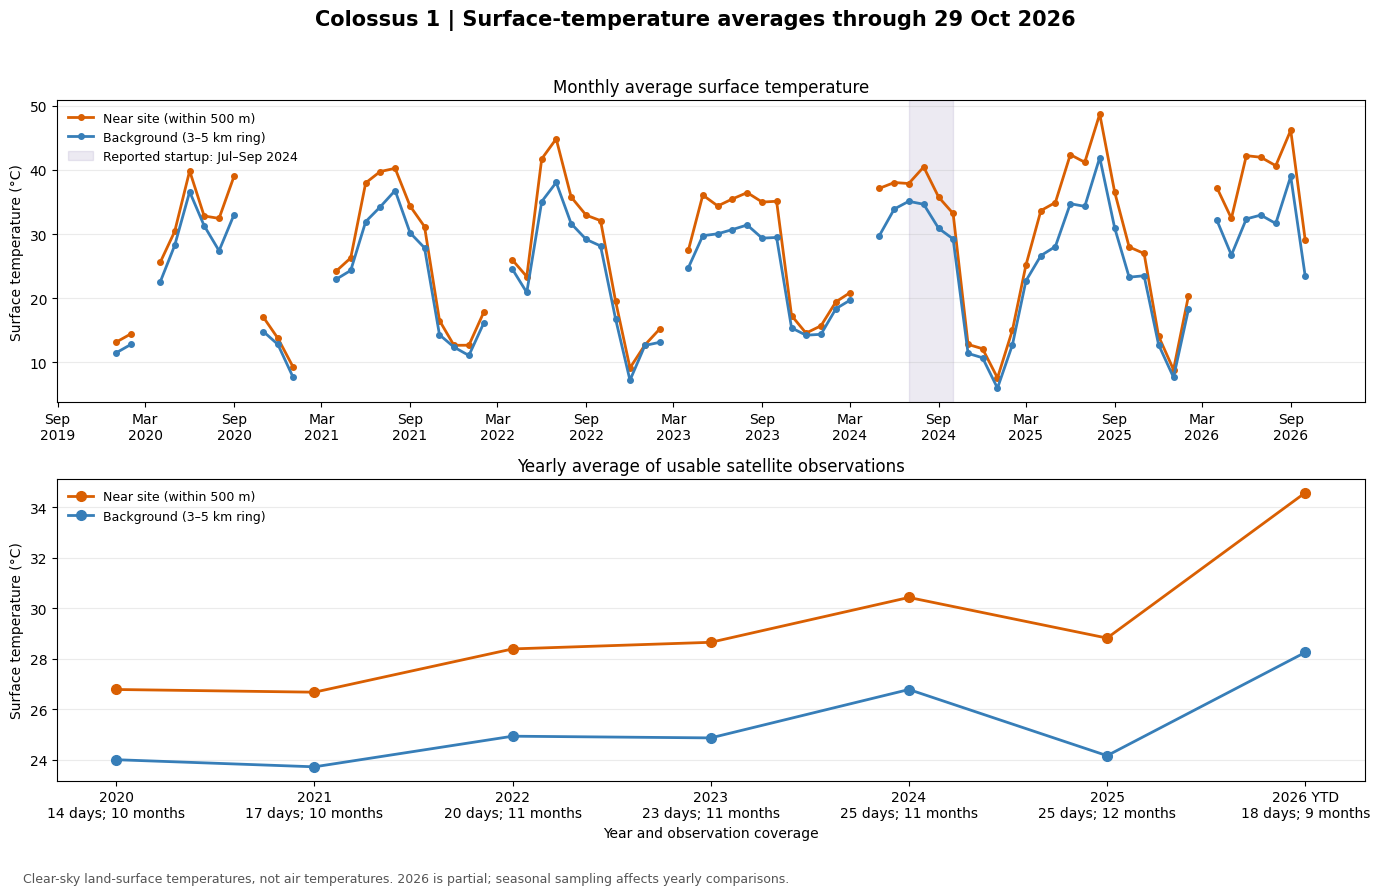

In [ ]:
# These averages use the same paired, coverage-screened daily observations
# as the timeline. No additional Earth Engine requests are required.
yearly = daily.groupby(daily.index.year).agg(
    near_C=("near_C", "mean"),
    background_C=("background_C", "mean"),
    excess_C=("excess_C", "mean"),
    valid_days=("excess_C", "count"),
)
yearly.index.name = "year"
yearly = yearly.reindex(range(pd.Timestamp(START_DATE).year,
                             (pd.Timestamp(END_DATE)-pd.Timedelta(days=1)).year+1))
yearly["valid_days"] = yearly["valid_days"].fillna(0).astype(int)
yearly["months_with_data"] = [
    daily.loc[daily.index.year == year].index.month.nunique()
    for year in yearly.index
]
yearly["months_meeting_monthly_minimum"] = [
    int(monthly.loc[monthly.index.year == year, "near_C"].notna().sum())
    for year in yearly.index
]
yearly["first_observation"] = [
    daily.loc[daily.index.year == year].index.min() for year in yearly.index
]
yearly["last_observation"] = [
    daily.loc[daily.index.year == year].index.max() for year in yearly.index
]
last_requested = pd.Timestamp(END_DATE) - pd.Timedelta(days=1)
yearly["period"] = [
    f"Year-to-date through {last_requested:%d %b %Y}"
    if year == last_requested.year and last_requested < pd.Timestamp(year=year,month=12,day=31)
    else "Full calendar-year window"
    for year in yearly.index
]
yearly.to_csv("Colossus_yearly_temperatures.csv")
print(f"Requested through: {last_requested:%d %B %Y}")
print(f"Latest usable paired observation: {daily.index.max():%d %B %Y}")
display(yearly.round(2))

fig_avg, (ax_month, ax_year) = plt.subplots(2,1,figsize=(14,9))
colors = {"near_C":"#d95f02", "background_C":"#377eb8"}
labels = {"near_C":"Near site (within 500 m)",
          "background_C":"Background (3–5 km ring)"}

for column in ["near_C","background_C"]:
    ax_month.plot(monthly.index,monthly[column],"-o",color=colors[column],
                  linewidth=2,markersize=4,label=labels[column])
    ax_year.plot(yearly.index,yearly[column],"-o",color=colors[column],
                 linewidth=2,markersize=7,label=labels[column])

ax_month.axvspan(pd.Timestamp("2024-07-01"),pd.Timestamp("2024-10-01"),
                 color="#8073ac",alpha=.15,label="Reported startup: Jul–Sep 2024")
ax_month.set(title="Monthly average surface temperature",ylabel="Surface temperature (°C)")
ax_month.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax_month.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax_month.legend(frameon=False,fontsize=9)

tick_labels = []
for year,row in yearly.iterrows():
    partial = row["period"].startswith("Year-to-date")
    tick_labels.append(f"{year}" + (" YTD" if partial else "") +
                       f"\n{int(row['valid_days'])} days; {int(row['months_with_data'])} months")
ax_year.set_xticks(yearly.index)
ax_year.set_xticklabels(tick_labels)
ax_year.set(title="Yearly average of usable satellite observations",
            ylabel="Surface temperature (°C)",xlabel="Year and observation coverage")
ax_year.legend(frameon=False,fontsize=9)
for ax in [ax_month,ax_year]:
    ax.grid(axis="y",alpha=.25)
fig_avg.suptitle(f"Colossus 1 | Surface-temperature averages through {last_requested:%d %b %Y}",
                 fontsize=15,weight="bold")
fig_avg.text(.02,.01,"Clear-sky land-surface temperatures, not air temperatures. 2026 is partial; seasonal sampling affects yearly comparisons.",
             fontsize=9,color="#555555")
fig_avg.tight_layout(rect=[0,.04,1,.96])
fig_avg.savefig("Colossus_monthly_yearly_averages.png",dpi=250,bbox_inches="tight")
plt.show()


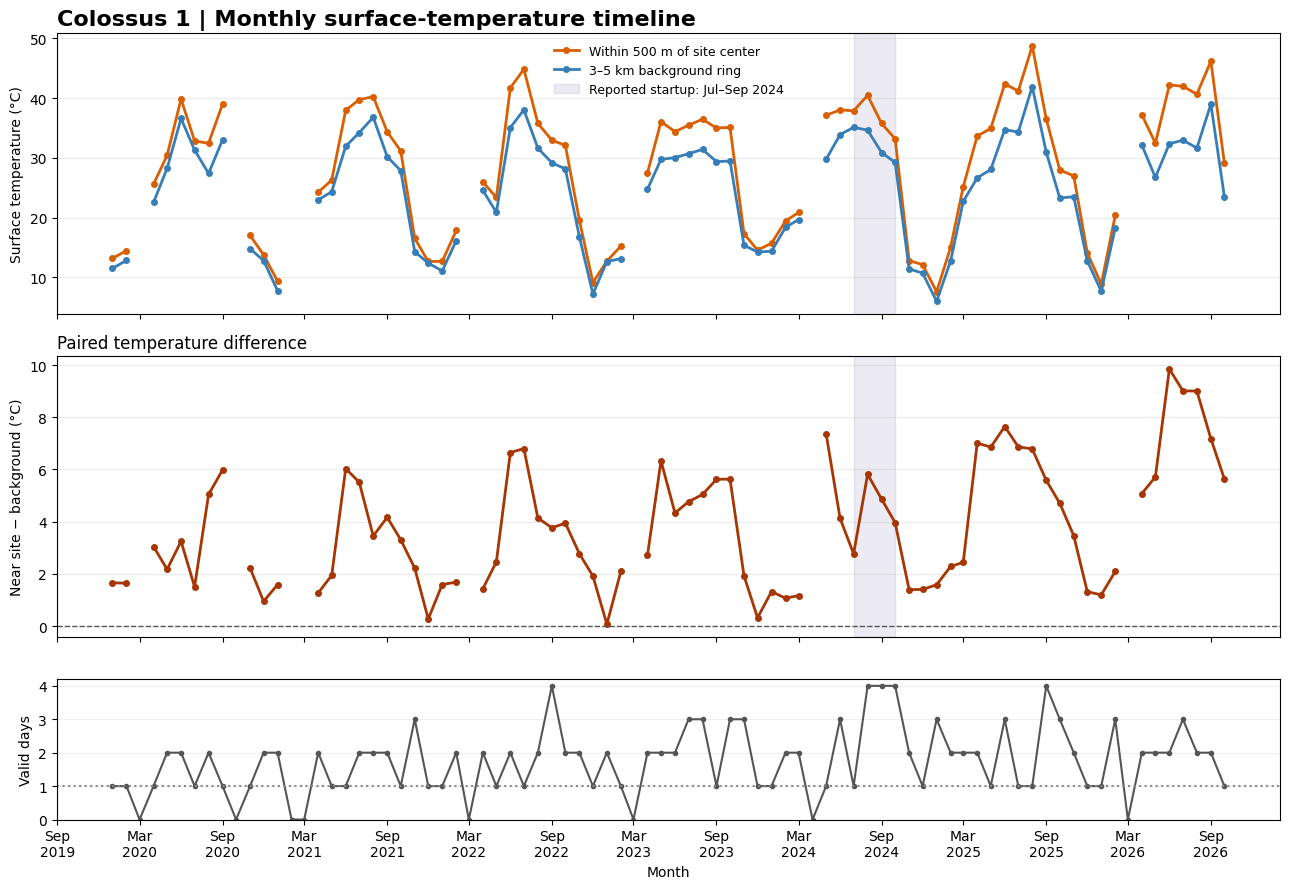

In [ ]:
plt.close("all")
fig, axes = plt.subplots(
    3,1,figsize=(13,9),sharex=True,
    gridspec_kw={"height_ratios":[2,2,1]})
ax_temp, ax_excess, ax_count = axes

ax_temp.plot(monthly.index, monthly["near_C"], "-o", color="#d95f02",
             linewidth=2, markersize=4, label="Within 500 m of site center")
ax_temp.plot(monthly.index, monthly["background_C"], "-o", color="#377eb8",
             linewidth=2, markersize=4, label="3–5 km background ring")
ax_temp.set_ylabel("Surface temperature (°C)")
ax_temp.set_title("Colossus 1 | Monthly surface-temperature timeline",
                  loc="left", fontsize=16, weight="bold")

ax_excess.plot(monthly.index, monthly["excess_C"], "-o",
               color="#a63603", linewidth=2, markersize=4)
ax_excess.axhline(0, color="#555555", linestyle="--", linewidth=1)
ax_excess.set_ylabel("Near site − background (°C)")
ax_excess.set_title("Paired temperature difference", loc="left")

for ax in [ax_temp, ax_excess]:
    ax.axvspan(pd.Timestamp("2024-07-01"),pd.Timestamp("2024-10-01"),
               color="#8073ac",alpha=.15,
               label="Reported startup: Jul–Sep 2024")
    ax.grid(axis="y",alpha=.25)
ax_temp.legend(frameon=False, fontsize=9)

ax_count.plot(monthly.index,monthly["valid_days"],"-o",
              color="#555555",markersize=3)
ax_count.axhline(MIN_VALID_DAYS_PER_MONTH,color="#888888",linestyle=":")
ax_count.set(ylabel="Valid days",xlabel="Month",ylim=(0,None))
ax_count.grid(axis="y",alpha=.2)
ax_count.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax_count.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.tight_layout()
fig.savefig("Colossus_temperature_timeline.png",dpi=250,bbox_inches="tight")
plt.show()

## 6. Summer heat maps (2023 versus 2025)
These maps use median summer composites, whereas the timeline uses monthly averages of paired acquisition means. They are different summaries.

The two temperature maps share the same color scale. The adjusted-change layer subtracts the change in the background mean. Only common valid pixels are compared. If background data are missing, the notebook still shows available temperatures/counts and omits the adjusted-change layer.

In [ ]:
def summer(year):
    c = collection.filterDate(f"{year}-06-01",f"{year}-09-01")
    if c.size().getInfo() == 0:
        raise ValueError(f"No summer scenes for {year}.")
    count = (c.count().rename("observations")
             .setDefaultProjection(CRS,None,SCALE).clip(roi))
    median = (c.median().setDefaultProjection(CRS,None,SCALE)
              .updateMask(count.gte(MIN_SUMMER_OBSERVATIONS)).clip(roi))
    return median,count

before, nb = summer(2023)
after, na = summer(2025)
common = before.mask().And(after.mask())
before,after = before.updateMask(common),after.updateMask(common)
def region_mean(image,region):
    return image.rename("value").reduceRegion(
        reducer=ee.Reducer.mean(),geometry=region,scale=SCALE,crs=CRS,
        maxPixels=100000000,tileScale=4).get("value")

refs = ee.Dictionary({
    "before":region_mean(before,reference),
    "after":region_mean(after,reference)}).getInfo()
thermal = {"min":20,"max":50,"palette":["253494","2c7fb8","41b6c4","ffffb2","fe9929","cc4c02","800026"]}
diverging = {"min":-5,"max":5,"palette":["2166ac","67a9cf","d1e5f0","f7f7f7","fddbc7","ef8a62","b2182b"]}
heat_map = geemap.Map(center=[LAT,LON],zoom=13)
heat_map.add_basemap("SATELLITE")
heat_map.addLayer(before,thermal,"Summer 2023 median °C",False)
heat_map.addLayer(after,thermal,"Summer 2025 median °C",False)
heat_map.addLayer(nb,{"min":0,"max":10},"2023 observation counts",False)
heat_map.addLayer(na,{"min":0,"max":10},"2025 observation counts",False)
change = None
if all(refs.get(k) is not None for k in ["before","after"]):
    raw = after.subtract(before)
    change = raw.subtract(refs["after"]-refs["before"]).rename("change_C")
    heat_map.addLayer(raw,diverging,"Raw summer change °C",False)
    heat_map.addLayer(change,diverging,"Background-adjusted summer change °C")
    heat_map.add_colorbar(diverging,label="Adjusted summer change (°C)")
    print("Summer background means:",refs)
else:
    heat_map.add_colorbar(thermal,label="Summer surface temperature (°C)")
    print("No usable common summer background. Adjusted-change map omitted; inspect counts.")
heat_map.addLayer(site,{"color":"cyan"},"Approximate site")
display(heat_map)

Summer background means: {'after': 36.60750609316933, 'before': 31.046840757503976}


Map(center=[35.06, -90.15639], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topri…

## 7. Download results
This downloads the line chart and the monthly/daily tables together. The scene statistics and analysis settings are included for reproducibility.

In [ ]:
import zipfile
Path("Colossus_settings.json").write_text(json.dumps({
    **config,
    "minimum_monthly_days":MIN_VALID_DAYS_PER_MONTH,
    "minimum_near_pixels":MIN_PIXELS_NEAR,
    "minimum_background_pixels":MIN_PIXELS_BACKGROUND,
    "minimum_summer_observations":MIN_SUMMER_OBSERVATIONS
},indent=2))
outputs = [
    "Colossus_monthly_yearly_averages.png",
    "Colossus_yearly_temperatures.csv",
    "Colossus_temperature_timeline.png",
    "Colossus_monthly_temperatures.csv",
    "Colossus_daily_temperatures.csv",
    "Colossus_all_scene_statistics.csv",
    "Colossus_settings.json",
]
with zipfile.ZipFile("Colossus_timeline_results.zip","w",zipfile.ZIP_DEFLATED) as archive:
    for filename in outputs:
        archive.write(filename)
files.download("Colossus_timeline_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Interpretation and sources
For a stronger study, use stable matched industrial controls, inspect changes in vegetation and roofing, analyze residential areas separately, and quantify uncertainty. A ring containing different land uses is not a causal control. The pre-existing industrial roof may already have been warm before the data center.

- [Landsat 9 Collection 2 Level 2: scaling, QA flags, missing-temperature caveats](https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC09_C02_T1_L2)
- [Earth Engine aggregation limits](https://developers.google.com/earth-engine/guides/usage#concurrent_aggregations)
- Approximate location cross-check: [former Electrolux plant](https://en.wikipedia.org/wiki/Frigidaire_Memphis_plant)
- Workflow adapted from section 5.1 of your supplied course tutorials.

**Validation status:** notebook structure and Python syntax checked locally. Live Earth Engine processing has not been run by the assistant; it requires your authenticated Colab runtime.